<a href="https://colab.research.google.com/github/jawad-glitch/uncertainty-aware-drone-nav/blob/main/kf_gps.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [48]:
import os
from google.colab import drive

drive.mount('/content/drive')

REPO_URL = "https://github.com/jawad-glitch/uncertainty-aware-drone-nav.git"
REPO_DIR = "/content/drive/MyDrive/uncertainty-aware-drone-nav"

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}
else:
    print("Repo exists, pulling")
    %cd {REPO_DIR}
    !git pull

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repo exists, pulling
/content/drive/MyDrive/uncertainty-aware-drone-nav
Already up to date.


In [49]:
!pip install filterpy

In [50]:
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.append("/content/drive/MyDrive/uncertainty-aware-drone-nav/src")
import sensors

data = dict(np.load("/content/drive/MyDrive/uncertainty-aware-drone-nav/results/pid_flight.npz"))
meas = sensors.make_sensors(data, seed=0)

dt = 1 / 48
n = len(data["time"])
print(n, meas["gps_valid"].mean())

1440 0.875


In [51]:
from filterpy.kalman import KalmanFilter

kf = KalmanFilter(dim_x=4, dim_z=2)           # state [x, y, vx, vy], measurement [x, y]
kf.F = np.array([[1, 0, dt, 0],
                 [0, 1, 0, dt],
                 [0, 0, 1,  0],
                 [0, 0, 0,  1]])              # constant-velocity model
kf.H = np.array([[1, 0, 0, 0],
                 [0, 1, 0, 0]])               # GPS sees only position
kf.R = np.eye(2) * 0.03**2                    # GPS noise variance (sigma from sensors.py)

# 1e-5 laggy, 1e-4 good, 1e-3 jittery
kf.Q = np.diag([0, 0, 1e-4, 1e-4])            # final guess

kf.x = np.array([meas["gps"][0, 0], meas["gps"][0, 1], 0, 0])
kf.P = np.diag([0.03**2, 0.03**2, 0.2**2, 0.2**2])

In [52]:
est = np.zeros((n, 4))
sig = np.zeros((n, 2))

for i in range(n):
    kf.predict()
    if meas["gps_valid"][i]:
        kf.update(meas["gps"][i, :2])
    est[i] = kf.x.ravel()
    sig[i] = np.sqrt(np.diag(kf.P))[:2]

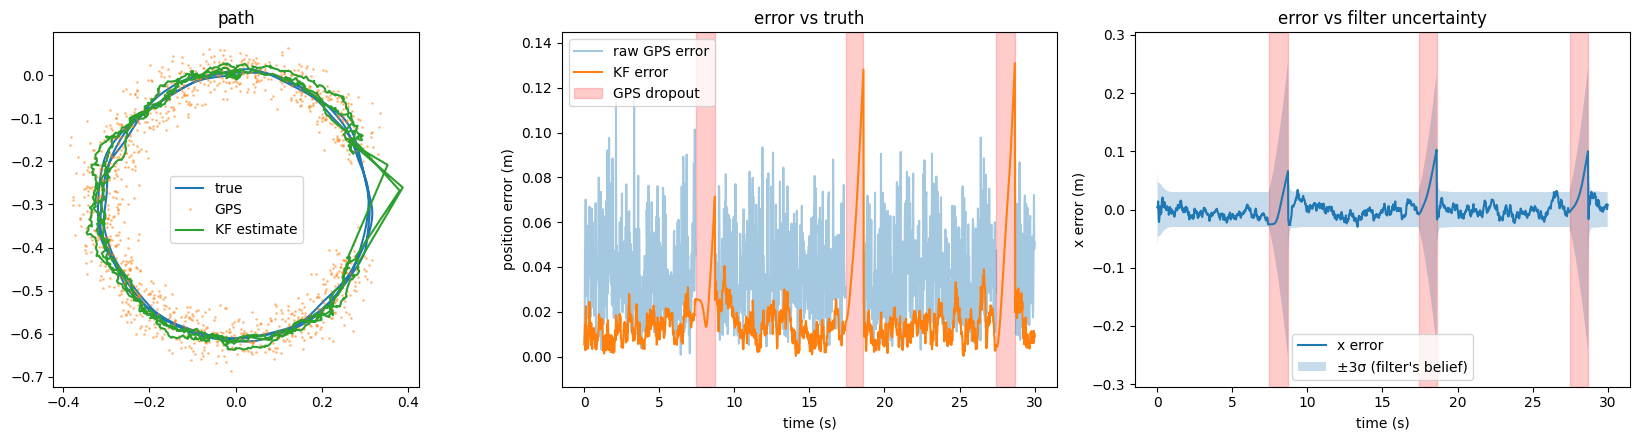

KF RMSE (all steps):       0.02535532026169259
KF RMSE (GPS steps only):  0.015204406541906499
raw GPS RMSE:              0.04250376319919097
KF RMSE inside dropout:    0.05937103903876878


In [53]:
t = data["time"]
valid = meas["gps_valid"]
true_xy = data["pos"][:, :2]

err = np.linalg.norm(est[:, :2] - true_xy, axis=1)
gps_err = np.linalg.norm(meas["gps"][:, :2] - true_xy, axis=1)   # NaN where dropped
err_x = est[:, 0] - true_xy[:, 0]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) path
ax[0].plot(true_xy[:, 0], true_xy[:, 1], label="true")
ax[0].plot(meas["gps"][:, 0], meas["gps"][:, 1], ".", ms=2, alpha=0.4, label="GPS")
ax[0].plot(est[:, 0], est[:, 1], label="KF estimate")
ax[0].set_aspect("equal")
ax[0].legend()
ax[0].set_title("path")

# 2) error over time
ax[1].plot(t, gps_err, alpha=0.4, label="raw GPS error")
ax[1].plot(t, err, label="KF error")
ax[1].fill_between(t, 0, 1, where=~valid, transform=ax[1].get_xaxis_transform(),
                   color="red", alpha=0.2, label="GPS dropout")
ax[1].set_xlabel("time (s)")
ax[1].set_ylabel("position error (m)")
ax[1].legend()
ax[1].set_title("error vs truth")

# 3) does the filter know how wrong it is?
ax[2].plot(t, err_x, label="x error")
ax[2].fill_between(t, -3 * sig[:, 0], 3 * sig[:, 0], alpha=0.25, label="±3σ (filter's belief)")
ax[2].fill_between(t, 0, 1, where=~valid, transform=ax[2].get_xaxis_transform(),
                   color="red", alpha=0.2)
ax[2].set_xlabel("time (s)")
ax[2].set_ylabel("x error (m)")
ax[2].legend()
ax[2].set_title("error vs filter uncertainty")

plt.tight_layout()
plt.show()

print("KF RMSE (all steps):      ", np.sqrt(np.mean(err**2)))
print("KF RMSE (GPS steps only): ", np.sqrt(np.mean(err[valid]**2)))
print("raw GPS RMSE:             ", np.sqrt(np.nanmean(gps_err**2)))
print("KF RMSE inside dropout:   ", np.sqrt(np.mean(err[~valid]**2)))